# Amplitudes and phase

Every operator in Notebooks 00 to 03 sends each bitstring to exactly one
bitstring. Written as a matrix, each one is a permutation matrix: its entries
are 0 or 1, with a single 1 in every row and every column. Even $Z$ fits this
pattern, apart from a sign. And that sign was a puzzle: $Z|1\rangle = -|1\rangle$,
yet no measurement in Notebook 01 could see it.

This notebook removes the restriction. What happens if the two entries of a
qubit's vector may be any complex numbers, not only 0 and 1? We will see what
a measurement returns then, which matrices are still allowed as operations,
and when a sign or a phase becomes visible. Everything after this notebook,
in this unit and in the rest of the course, rests on these ideas.

## Before you start

This notebook assumes:

- [Notebook 00](00_Bits_and_Basis_States.ipynb): basis states $|0\rangle$ and
  $|1\rangle$, kets, $a^\dagger$ and $a$, circuits, measurement, shots,
  counts, and the Sampler.
- [Notebook 01](01_One_Bit_Operators.ipynb): bras and outer products, the
  projectors $n = |1\rangle\langle 1|$ and $\bar n = |0\rangle\langle 0|$,
  $X = a + a^\dagger$, $Z = \bar n - n$, and the Z-basis measurement.
- [Notebook 02](02_Reversible_Logic.ipynb): permutation matrices and
  reversible operations.
- Complex numbers: the conjugate $\bar z$, the modulus $|z|$ with
  $|z|^2 = z\bar z$, and Euler's formula $e^{i\varphi} = \cos\varphi + i\sin\varphi$.

Quick check:

1. What is $|(1+i)/2|^2$?
2. What are $X|0\rangle$ and $Z|1\rangle$?
3. What is $e^{i\pi}$?

Answers: $(1+i)(1-i)/4 = 2/4 = 1/2$; $|1\rangle$ and $-|1\rangle$; $-1$.

After this notebook you will be able to:

1. Compute the probability of each measurement result from the two complex
   numbers that describe a qubit.
2. Decide whether a given matrix is allowed as an operation on a quantum
   computer, and build new operations from $a$, $a^\dagger$, $n$ and $\bar n$.
3. Explain why multiplying a whole state by $e^{i\gamma}$ changes nothing that
   can be measured, while a sign or a phase on only one part of the state can.
4. Place a qubit's state on a sphere using two angles computed from its two
   complex numbers.

## Setup

The same setup as Notebook 00, plus `Statevector`, which this notebook defines.

In [1]:
import sys
from pathlib import Path
from types import SimpleNamespace

import numpy as np
from qiskit import ClassicalRegister, QuantumCircuit, QuantumRegister
from qiskit.quantum_info import Statevector
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# _runtime.py (in ../scripts) decides where circuits run:
# Aer, and IBM hardware if asked.
# Run this notebook from its own folder (the default in Jupyter and VS Code).
sys.path.insert(0, str(Path.cwd().parent / "scripts"))
from _runtime import get_targets

np.set_printoptions(precision=3, suppress=True)

SETTINGS = SimpleNamespace(
    shots=4096,                  # runs of each circuit
    precision=0.02,              # used from Notebook 09 on
    backend="ibm_rensselaer",
    name="default",              # saved IBM account name
    skip_hardware=True,          # set to False to also run on IBM hardware
    poll_interval=20,            # seconds between hardware status checks
)
targets = get_targets(SETTINGS)
print("Running on:", [t.label for t in targets])

Running on: ['aer']


## Amplitudes and the Born rule

In Notebook 00 a qubit's vector was either $(1, 0)^T$ or $(0, 1)^T$. Suppose
instead the vector is $(1/\sqrt2,\ 1/\sqrt2)^T$. That is

$$\tfrac{1}{\sqrt2}\begin{pmatrix}1\\0\end{pmatrix} + \tfrac{1}{\sqrt2}\begin{pmatrix}0\\1\end{pmatrix} = \tfrac{1}{\sqrt2}|0\rangle + \tfrac{1}{\sqrt2}|1\rangle,$$

a combination of both basis states at once. What should a measurement of
such a qubit return?

A general one-qubit state is

$$|\psi\rangle = \alpha|0\rangle + \beta|1\rangle = \begin{pmatrix}\alpha\\ \beta\end{pmatrix},$$

where $\alpha$ and $\beta$ are complex numbers. They are the *amplitudes* of
the state: $\alpha$ is the amplitude of $|0\rangle$ and $\beta$ the amplitude
of $|1\rangle$. A state with more than one nonzero amplitude is a
*superposition*. In words: a superposition is a vector that is a weighted sum
of several basis states, with complex weights.

The amplitudes are not probabilities themselves; they can be negative or
complex. The link to measurement is the *Born rule*: a Z-basis measurement of
$|\psi\rangle$ returns 0 with probability $|\alpha|^2$ and 1 with probability
$|\beta|^2$. Each shot gives one of the two results at random. After the
measurement the qubit is in the basis state that was measured, $|0\rangle$ or
$|1\rangle$, so measuring again gives the same result.

The two probabilities must add to 1, which requires *normalization*:

$$|\alpha|^2 + |\beta|^2 = 1.$$

The basis states fit this picture as the special cases $\alpha = 1, \beta = 0$
and $\alpha = 0, \beta = 1$, where the Born rule gives one result with
probability 1. That is why every shot in Notebooks 00 to 03 was predictable.

The same rule covers several qubits. An $n$-qubit state is a vector with
$2^n$ entries, one amplitude for each bitstring (Notebook 00), so it can be
written as a sum $\sum_x c_x|x\rangle$ over the bitstrings $x$. Measuring
every qubit returns the bitstring $x$ with probability $|c_x|^2$, and
normalization reads $\sum_x |c_x|^2 = 1$. For example, the two-qubit state
$\tfrac12(|00\rangle + |01\rangle + |10\rangle + |11\rangle)$ has amplitude
$\tfrac12$ on each of the four bitstrings, so each is measured with
probability $\tfrac14$.

### Example 1: probabilities from complex amplitudes

**Problem.** A qubit is in the state $|\psi\rangle = \tfrac{1}{\sqrt2}|0\rangle + \tfrac{i}{\sqrt2}|1\rangle$.
What are the probabilities of measuring 0 and 1, and is the state normalized?

**Plan.** Apply the Born rule to each amplitude, using $|z|^2 = z\bar z$, then
add the results.

**Solution.**

**Subgoal 1: the probability of 0.**

1. The amplitude of $|0\rangle$ is $\alpha = 1/\sqrt2$, a real number, so its
   conjugate is itself.
2. Multiply: $|\alpha|^2 = \tfrac{1}{\sqrt2}\cdot\tfrac{1}{\sqrt2} = \tfrac12$.

**Subgoal 2: the probability of 1.**

3. The amplitude of $|1\rangle$ is $\beta = i/\sqrt2$; its conjugate is
   $\bar\beta = -i/\sqrt2$.
4. Multiply: $|\beta|^2 = \tfrac{i}{\sqrt2}\cdot\tfrac{-i}{\sqrt2} = \tfrac{-i^2}{2} = \tfrac{1}{2}$,
   using $i^2 = -1$.

**Subgoal 3: normalization.**

5. Add: $|\alpha|^2 + |\beta|^2 = \tfrac12 + \tfrac12 = 1$. The state is
   normalized.

**Check.** The vector $(1/\sqrt2,\ 1/\sqrt2)^T$ from the start of the section
also gives $\tfrac12$ and $\tfrac12$. Multiplying an amplitude by $i$ changed
its direction in the complex plane but not its modulus, so the probabilities
did not change.

**Takeaway.** Only the modulus of each amplitude enters the probabilities.
Whatever information the complex directions of $\alpha$ and $\beta$ carry, a
single Z-basis measurement cannot see it.

In [2]:
def probabilities(state):
    """Born rule for a one-qubit state: P(0) = |alpha|^2, P(1) = |beta|^2."""
    return np.abs(state) ** 2


examples = {
    "(|0> + i|1>)/sqrt2": np.array([1, 1j]) / np.sqrt(2),
    "(3|0> + 4i|1>)/5": np.array([3, 4j]) / 5,
}
for name, state in examples.items():
    p = probabilities(state)
    print(f"{name:20s} P(0) = {p[0]:.3f}  P(1) = {p[1]:.3f}  sum = {p.sum():.3f}")

(|0> + i|1>)/sqrt2   P(0) = 0.500  P(1) = 0.500  sum = 1.000
(3|0> + 4i|1>)/5     P(0) = 0.360  P(1) = 0.640  sum = 1.000


**Check.** A qubit is in the state $\tfrac35|0\rangle - \tfrac45|1\rangle$.
What is the probability of measuring 1?

## The conjugate transpose and the inner product

Notebook 01 defined the bra $\langle u|$ as the transpose of the ket $|u\rangle$
and the inner product $\langle u|v\rangle$ as the sum of products of
matching entries. That worked for vectors with real entries. Try it on
$|\psi\rangle = (1, i)^T/\sqrt2$ from Example 1: the sum of products of
matching entries is $(1\cdot 1 + i\cdot i)/2 = 0$. So the real-vector rule
gives this normalized state a length of zero, which is wrong. The fix is to
take the complex conjugate of the left vector.

The *conjugate transpose* of a matrix $M$, written $M^\dagger$ ("M dagger"),
is the transpose of $M$ with every entry replaced by its complex conjugate:
$(M^\dagger)_{jk} = \overline{M_{kj}}$. In words: flip the matrix across its
diagonal and conjugate every entry. For a matrix with real entries, the
conjugate transpose is the transpose.

Like the transpose, the conjugate transpose of a product reverses the order:
$(AB)^\dagger = B^\dagger A^\dagger$. The transpose rule $(AB)^T = B^TA^T$
gives the order, and conjugating every entry of a product is the same as
conjugating every entry of each factor, because $\overline{zw} = \bar z\,\bar w$.

The matrix $a$ from Notebook 00 has real entries, so its conjugate transpose
is its transpose, which is exactly the creation operator. That is where the
name $a^\dagger$ comes from.

With the dagger, the bra of a ket is $\langle\psi| = |\psi\rangle^\dagger$, a
row vector of conjugated amplitudes, and the *inner product* of two states is

$$\langle\phi|\psi\rangle = \sum_k \overline{\phi_k}\,\psi_k .$$

For one state with itself, $\langle\psi|\psi\rangle = |\alpha|^2 + |\beta|^2$,
so normalization reads $\langle\psi|\psi\rangle = 1$.

Two states are *orthogonal* when $\langle\phi|\psi\rangle = 0$. The *overlap*
of two normalized states is $|\langle\phi|\psi\rangle|^2$, a number between 0
and 1. It cannot be negative because it is a squared modulus, and it cannot
exceed 1 because of the Cauchy-Schwarz inequality,
$|\langle\phi|\psi\rangle| \le \sqrt{\langle\phi|\phi\rangle}\,\sqrt{\langle\psi|\psi\rangle}$,
which holds for complex vectors as it does for real ones (we use it without
proof); for normalized states the right side is 1.

For a basis state the overlap is the Born rule again:
$|\langle 0|\psi\rangle|^2 = |\alpha|^2$ and $|\langle 1|\psi\rangle|^2 = |\beta|^2$.
In general, the overlap is the probability that a measurement which tells
$|\phi\rangle$ apart from the states orthogonal to it returns the result for
$|\phi\rangle$. Notebook 06 shows how to build such a measurement.

In [3]:
psi = np.array([1, 1j]) / np.sqrt(2)
# The wrong rule (no conjugation) gives 0; np.vdot conjugates its first argument.
print(f"without conjugation: {abs(np.sum(psi * psi)):.3f}")
print(f"with conjugation   : {np.vdot(psi, psi).real:.3f}")

a = np.array([[0, 1], [0, 0]])
print("conjugate transpose of a:\n", a.conj().T)

without conjugation: 0.000
with conjugation   : 1.000
conjugate transpose of a:
 [[0 0]
 [1 0]]


**Check.** Are $(|0\rangle + i|1\rangle)/\sqrt2$ and $(|0\rangle - i|1\rangle)/\sqrt2$
orthogonal?

## Which matrices are allowed: unitary operators

An operation on a qubit must turn every normalized state into a normalized
state, or the probabilities would stop adding to 1. Which matrices do that?

Apply a matrix $U$ to $|\psi\rangle$ and compute the squared length of the
result. The bra of $U|\psi\rangle$ is $\langle\psi|U^\dagger$, by the
reverse-order rule $(AB)^\dagger = B^\dagger A^\dagger$, so the squared length is

$$\langle\psi|U^\dagger U|\psi\rangle .$$

If $U^\dagger U = I$, this equals $\langle\psi|\psi\rangle = 1$ for every
state. A matrix with this property is a *unitary operator*:

$$U^\dagger U = I .$$

In words: a unitary operator is a matrix whose conjugate transpose is its
inverse.

The condition is also necessary: a matrix that keeps every state normalized
must satisfy $U^\dagger U = I$. We take this direction as given; the idea is
that a matrix that preserves the length of every vector also preserves the
inner product of every pair of vectors, and the entries of $U^\dagger U$ are
the inner products $\langle Ue_j|Ue_k\rangle$ of the transformed basis vectors
$e_j$. So every gate a quantum computer applies is a unitary operator.

The same entries give a quick test. Entry $(j, k)$ of $U^\dagger U$ is the
inner product of column $j$ of $U$ with column $k$, so $U^\dagger U = I$ says
exactly that the columns of $U$ are normalized and orthogonal to each other.
Later checks use this column test.

Because $U^\dagger$ is the inverse of $U$, applying $U^\dagger$ after $U$
returns every state to where it started. This is where the restriction that
[Notebook 02](02_Reversible_Logic.ipynb) took as given comes from: every gate
can be undone, because every gate is unitary.

The permutation matrices of Notebook 02 are unitary: their entries are real,
so $U^\dagger = U^T$, and the transpose of a permutation matrix is the
permutation that undoes it. Unitary operators include far more than
permutations, though, because their entries may be any complex numbers that
satisfy $U^\dagger U = I$. This is the extra freedom a quantum computer has
over a reversible classical computer.

Not every matrix qualifies. The annihilation operator $a$ is not unitary:
$a^\dagger a = n$ (Notebook 01), which is not $I$. Neither $a$ nor $a^\dagger$
is an operation a quantum computer can apply. They are the parts from which
unitary operators are built, as $X = a + a^\dagger$ already showed.

## New operators from the same parts

With complex coefficients allowed, the same four parts $a$, $a^\dagger$, $n$
and $\bar n$ give new unitary operators. Each one below appears in every later
notebook.

**The Pauli $Y$ operator.** Combine $a^\dagger$ and $a$ with a factor $i$:

$$Y = i\,(a^\dagger - a) = \begin{pmatrix}0 & -i\\ i & 0\end{pmatrix},\qquad Y|0\rangle = i|1\rangle,\quad Y|1\rangle = -i|0\rangle .$$

In words: $Y$ flips the bit, like $X$, and multiplies the result by $i$ or
$-i$. It is the first operator with a complex (not real) coefficient. $Y$ is the
third Pauli operator, with $X$ and $Z$ from Notebook 01.

**The Hadamard operator.** The *Hadamard* operator is

$$H = \frac{X + Z}{\sqrt2} = \frac{1}{\sqrt2}\begin{pmatrix}1 & 1\\ 1 & -1\end{pmatrix}.$$

$Z$ already has the entry $-1$ and $Y$ has $\pm i$, but every entry of those
has modulus 0 or 1. $H$ is the first operator with entries of another modulus,
$1/\sqrt2$, and it creates superpositions: applied to each qubit of $|00\rangle$
it gives the four-bitstring state with amplitudes $\tfrac12$ from the Born rule
section, since $H|0\rangle \otimes H|0\rangle = \tfrac12(|0\rangle + |1\rangle)\otimes(|0\rangle + |1\rangle)$.
Its results on the basis states get names of their own, and so do two related
states:

$$|+\rangle = \tfrac{1}{\sqrt2}(|0\rangle + |1\rangle),\quad |-\rangle = \tfrac{1}{\sqrt2}(|0\rangle - |1\rangle),\quad |{+i}\rangle = \tfrac{1}{\sqrt2}(|0\rangle + i|1\rangle),\quad |{-i}\rangle = \tfrac{1}{\sqrt2}(|0\rangle - i|1\rangle).$$

**The phase gate.** The *phase gate* multiplies the amplitude of $|1\rangle$ by
$e^{i\varphi}$ and leaves the amplitude of $|0\rangle$ alone:

$$P(\varphi) = \bar n + e^{i\varphi}\, n = \begin{pmatrix}1 & 0\\ 0 & e^{i\varphi}\end{pmatrix}.$$

Three angles have their own names: $S = P(\pi/2)$, with $e^{i\pi/2} = i$;
its conjugate transpose $S^\dagger = P(-\pi/2)$, with $e^{-i\pi/2} = -i$; and
$Z = P(\pi)$, since $e^{i\pi} = -1$ makes $P(\pi) = \bar n - n$.

In Qiskit these are `circuit.y`, `circuit.h`, `circuit.p(phi, k)`,
`circuit.s`, `circuit.sdg` (S-dagger), and `circuit.z`.

### Example 2: what $H$ does, and why it is allowed

**Problem.** Compute $H|0\rangle$ and $H|1\rangle$ from $H = (X + Z)/\sqrt2$,
and show that $H$ is unitary.

**Plan.** Apply $X$ and $Z$ separately and add, using the results of
Notebook 01. Then compute $H^\dagger H$.

**Solution.**

**Subgoal 1: $H$ on the basis states.**

1. By linearity, $H|0\rangle = \tfrac{1}{\sqrt2}(X|0\rangle + Z|0\rangle)$.
2. Use $X|0\rangle = |1\rangle$ and $Z|0\rangle = |0\rangle$:
   $H|0\rangle = \tfrac{1}{\sqrt2}(|1\rangle + |0\rangle) = |+\rangle$.
3. In the same way, $H|1\rangle = \tfrac{1}{\sqrt2}(X|1\rangle + Z|1\rangle) = \tfrac{1}{\sqrt2}(|0\rangle - |1\rangle) = |-\rangle$,
   using $X|1\rangle = |0\rangle$ and $Z|1\rangle = -|1\rangle$.

**Subgoal 2: unitarity.**

4. The entries of $H$ are real and $H$ equals its own transpose, so
   $H^\dagger = H$ and $H^\dagger H = H^2$.
5. Expand the square: $H^2 = \tfrac12(X + Z)(X + Z) = \tfrac12(X^2 + XZ + ZX + Z^2)$.
6. Use $X^2 = Z^2 = I$ (Notebook 01): $H^2 = \tfrac12(2I + XZ + ZX)$.
7. Multiply the matrices: $XZ = \begin{pmatrix}0&-1\\1&0\end{pmatrix}$ and
   $ZX = \begin{pmatrix}0&1\\-1&0\end{pmatrix}$, so $XZ + ZX = 0$.
8. Therefore $H^2 = I$, and $H$ is unitary.

**Check.** The columns of the matrix $H$ are $H|0\rangle$ and $H|1\rangle$:
$(1, 1)^T/\sqrt2$ and $(1, -1)^T/\sqrt2$, which matches steps 2 and 3. Each
column is normalized, and their inner product is $(1 - 1)/2 = 0$.

**Self-explanation prompt.** Step 8 says $H^2 = I$. What does that predict
for a circuit that applies $H$ twice to $|0\rangle$? **Answer.** The qubit
returns to $|0\rangle$, so every shot measures 0. The experiment tests this.

**Takeaway.** $H$ turns each basis state into an equal superposition, and
because $H^2 = I$ it also turns each of those superpositions back.

In [4]:
a_dag = a.T
n, n_bar = a_dag @ a, a @ a_dag
I, X, Z = np.eye(2), a + a_dag, n_bar - n
Y = 1j * (a_dag - a)
H = (X + Z) / np.sqrt(2)


def phase_gate(phi):
    return n_bar + np.exp(1j * phi) * n


S, S_dag = phase_gate(np.pi / 2), phase_gate(-np.pi / 2)


def is_unitary(m):
    return np.allclose(m.conj().T @ m, np.eye(len(m)))


matrices = {"Y": Y, "H": H, "S": S, "S_dag": S_dag, "P(pi) - Z": phase_gate(np.pi) - Z}
for name, m in matrices.items():
    print(f"{name}:\n{np.round(m, 3) + 0}")   # + 0 hides -0.0
for name, m in {"Y": Y, "H": H, "S": S, "a": a}.items():
    print(f"{name} unitary? {is_unitary(m)}")
print("H|0> =", H @ [1, 0], "  H|1> =", H @ [0, 1])

Y:
[[0.+0.j 0.-1.j]
 [0.+1.j 0.+0.j]]
H:
[[ 0.707  0.707]
 [ 0.707 -0.707]]
S:
[[1.+0.j 0.+0.j]
 [0.+0.j 0.+1.j]]
S_dag:
[[1.+0.j 0.+0.j]
 [0.+0.j 0.-1.j]]
P(pi) - Z:
[[0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j]]
Y unitary? True
H unitary? True
S unitary? True
a unitary? False
H|0> = [0.707 0.707]   H|1> = [ 0.707 -0.707]


**Check.** What is $S|+\rangle$? Write the answer as one of the four named
states.

## Global phase and relative phase

Now we can answer the puzzle from Notebook 01. Multiply a whole state by a
number $e^{i\gamma}$ of modulus 1. The amplitudes become $e^{i\gamma}\alpha$
and $e^{i\gamma}\beta$, and the probabilities do not change, since
$|e^{i\gamma}\alpha|^2 = |e^{i\gamma}|^2|\alpha|^2 = |\alpha|^2$. Any operator
applied later acts linearly, so $U(e^{i\gamma}|\psi\rangle) = e^{i\gamma}U|\psi\rangle$,
and the factor rides along unchanged through every later step and every
measurement.

A common factor $e^{i\gamma}$ on the whole state is a *global phase*. No
measurement can ever detect it, so two states that differ only by a global
phase count as the same state: every measurement, after any sequence of
gates, gives them the same probabilities. On the input $|1\rangle$,
$Z|1\rangle = -|1\rangle$ is a global phase, with $e^{i\gamma} = -1$, which is
why Notebook 01, which used only bitstrings as inputs, could not see it. On a
superposition the same $Z$ multiplies only the $|1\rangle$ amplitude by $-1$,
which is a different kind of phase, as the next paragraph shows.

A phase on only one amplitude is different. The states $|+\rangle$ and
$|-\rangle$ have the same amplitudes of $|0\rangle$, and amplitudes of
$|1\rangle$ that differ by the factor $-1$. The phase of $\beta$ compared with
the phase of $\alpha$ is the *relative phase* of a state: 0 for $|+\rangle$,
$\pi$ for $|-\rangle$, $\pi/2$ for $|{+i}\rangle$. In fact $|-\rangle = Z|+\rangle$:
on $|+\rangle$, $Z$ changes the relative phase from 0 to $\pi$. Probabilities
in the Z basis do not depend on the relative phase. Later operations can, as
the next example shows.

### Example 3: a relative phase that changes the result

**Problem.** Compute $H|+\rangle$ and $H|-\rangle$. What does a Z-basis
measurement return in each case?

**Plan.** Write each state in terms of $|0\rangle$ and $|1\rangle$, apply $H$
by linearity using Example 2, and collect the amplitudes.

**Solution.**

**Subgoal 1: $H|+\rangle$.**

1. By linearity, $H|+\rangle = \tfrac{1}{\sqrt2}(H|0\rangle + H|1\rangle) = \tfrac{1}{\sqrt2}(|+\rangle + |-\rangle)$.
2. Substitute the definitions: $\tfrac{1}{\sqrt2}\cdot\tfrac{1}{\sqrt2}\big[(|0\rangle + |1\rangle) + (|0\rangle - |1\rangle)\big]$.
3. Collect terms: the $|0\rangle$ amplitudes add to $\tfrac12 + \tfrac12 = 1$
   and the $|1\rangle$ amplitudes add to $\tfrac12 - \tfrac12 = 0$. So
   $H|+\rangle = |0\rangle$, and every shot returns 0.

**Subgoal 2: $H|-\rangle$.**

4. By linearity, $H|-\rangle = \tfrac{1}{\sqrt2}(H|0\rangle - H|1\rangle) = \tfrac{1}{\sqrt2}(|+\rangle - |-\rangle)$.
5. Substitute: $\tfrac12\big[(|0\rangle + |1\rangle) - (|0\rangle - |1\rangle)\big]$.
6. Collect terms: the $|0\rangle$ amplitudes cancel and the $|1\rangle$
   amplitudes add to 1. So $H|-\rangle = |1\rangle$, and every shot returns 1.

**Check.** $H^2 = I$ (Example 2), and $|+\rangle = H|0\rangle$, so
$H|+\rangle = H^2|0\rangle = |0\rangle$. The same argument gives
$H|-\rangle = H^2|1\rangle = |1\rangle$.

**Takeaway.** $|+\rangle$ and $|-\rangle$ give identical Z-basis counts, yet
after one more $H$ they give opposite, certain results. The relative phase is
real information: it decides which amplitudes cancel. Notebook 06 studies this
cancellation in detail.

A common mistake is to conclude that phase never matters, because the Born
rule uses only $|\text{amplitude}|^2$. That is right for a global phase and
wrong for a relative phase. The mistake is tempting because a single Z-basis
measurement, the only measurement used so far, cannot see either one.
Example 3 shows that an $H$ before the measurement converts a relative phase
into a difference in counts.

A second common mistake is to think a superposition such as $|+\rangle$ is a
coin that is secretly 0 or 1, and that the measurement only reveals which. If
that were true, a qubit in $|+\rangle$ would really be $|0\rangle$ half the
time and $|1\rangle$ half the time. A following $H$ would then give
$H|0\rangle$ or $H|1\rangle$, each of which measures 0 with probability
$\tfrac12$, so the counts would be 50/50. Example 3 predicts 0 on every shot
instead. The experiment below decides between the two predictions. The coin
picture is tempting because a single measurement of $|+\rangle$ does look
exactly like a coin flip.

**Check.** Is $-|+\rangle$ the same state as $|+\rangle$ up to a global
phase? Is $|-\rangle$?

## The Bloch sphere

A qubit's state has two complex amplitudes, four real numbers in all.
Normalization removes one, and the global phase removes another, which leaves
two. Two numbers can be drawn as a point on a sphere, and the picture helps
with everything that follows.

Three steps reduce the four numbers to two. First, remove the global phase:
write $\alpha = |\alpha|e^{i\gamma}$. Factoring out $e^{i\gamma}$ makes the
amplitude of $|0\rangle$ real and not negative, and changes nothing
measurable.

Second, use normalization. Since $|\alpha|^2 + |\beta|^2 = 1$ and both
moduli lie between 0 and 1, there is an angle $\theta$ between 0 and $\pi$ with
$|\alpha| = \cos(\theta/2)$ and $|\beta| = \sin(\theta/2)$, because
$\cos^2 + \sin^2 = 1$. Writing the moduli with the half angle $\theta/2$, which
covers 0 to $\pi/2$ where cosine and sine are both not negative, lets $\theta$
itself run from 0 to $\pi$, the full range of a polar angle on a sphere. That
choice is what makes the states fill a whole sphere, and below it puts
orthogonal states at opposite points.

Third, keep the relative phase. What remains of $\beta$ after the
global phase is removed is a phase $e^{i\varphi}$, so every one-qubit state can
be written

$$|\psi\rangle = e^{i\gamma}\left(\cos\tfrac{\theta}{2}\,|0\rangle + e^{i\varphi}\sin\tfrac{\theta}{2}\,|1\rangle\right),\qquad 0 \le \theta \le \pi,\quad 0 \le \varphi < 2\pi .$$

The *Bloch sphere* is the sphere of radius 1 on which this state is the point
with polar angle $\theta$ and azimuthal angle $\varphi$. These are spherical
coordinates: the polar angle $\theta$ is the angle between the point's
direction and the $+z$ axis (the north pole), and the azimuthal angle
$\varphi$ is measured around the $z$ axis, starting from the $+x$ axis. In
Cartesian coordinates the point is

$$(x, y, z) = (\sin\theta\cos\varphi,\ \sin\theta\sin\varphi,\ \cos\theta).$$

In words: the height on the sphere sets the measurement probabilities, and
the direction around the vertical axis is the relative phase. The global
phase does not appear at all. The height statement follows from the
double-angle formula:
$z = \cos\theta = \cos^2\tfrac{\theta}{2} - \sin^2\tfrac{\theta}{2} = P(0) - P(1)$.

| State | $\theta$ | $\varphi$ | Point on the sphere |
|---|---|---|---|
| $\lvert 0\rangle$ | 0 | any | north pole, $+z$ |
| $\lvert 1\rangle$ | $\pi$ | any | south pole, $-z$ |
| $\lvert +\rangle$ | $\pi/2$ | 0 | $+x$ |
| $\lvert -\rangle$ | $\pi/2$ | $\pi$ | $-x$ |
| $\lvert {+i}\rangle$ | $\pi/2$ | $\pi/2$ | $+y$ |
| $\lvert {-i}\rangle$ | $\pi/2$ | $3\pi/2$ | $-y$ |

The six states in the table sit on the three axes: $|0\rangle$ and
$|1\rangle$ on the $z$ axis, $|\pm\rangle$ on the $x$ axis, and $|{\pm i}\rangle$
on the $y$ axis. Later notebooks refer to them by these axes.

The phase gate $P(\varphi_0)$ adds $\varphi_0$ to the relative phase, so on
the sphere it turns every point by the angle $\varphi_0$ about the vertical
axis. $S$ turns $|+\rangle$ to $|{+i}\rangle$, a quarter turn.

Orthogonal states sit at opposite points. Take the state with angles
$(\theta, \varphi)$ and the angles $(\pi - \theta,\ \varphi + \pi)$ of the
opposite point. Using $\cos\tfrac{\pi - \theta}{2} = \sin\tfrac{\theta}{2}$,
$\sin\tfrac{\pi - \theta}{2} = \cos\tfrac{\theta}{2}$ and $e^{i\pi} = -1$, the
two states are

$$|\psi\rangle = \cos\tfrac{\theta}{2}|0\rangle + e^{i\varphi}\sin\tfrac{\theta}{2}|1\rangle,\qquad
|\psi'\rangle = \sin\tfrac{\theta}{2}|0\rangle - e^{i\varphi}\cos\tfrac{\theta}{2}|1\rangle,$$

and their inner product, conjugating the left state, is

$$\langle\psi|\psi'\rangle = \cos\tfrac{\theta}{2}\sin\tfrac{\theta}{2} - e^{-i\varphi}e^{i\varphi}\sin\tfrac{\theta}{2}\cos\tfrac{\theta}{2} = 0 .$$

More generally, define the *angle between two states* $|\phi\rangle$ and
$|\psi\rangle$ as the angle $\delta$ between 0 and $\pi/2$ with
$\cos\delta = |\langle\phi|\psi\rangle|$. For real unit vectors this is the
usual angle between arrows (or its supplement). On the Bloch sphere the two
points are $2\delta$ apart, so the overlap is
$|\langle\phi|\psi\rangle|^2 = \cos^2(\text{half the angle between the two points})$.
We use this rule without proof; the code below checks it on random pairs, and
orthogonal states ($\delta = \pi/2$, points $\pi$ apart) are one case of it.

### Example 4: where $|{-i}\rangle$ sits on the sphere

**Problem.** Find $\theta$ and $\varphi$ for $|{-i}\rangle = \tfrac{1}{\sqrt2}(|0\rangle - i|1\rangle)$,
and the Cartesian point.

**Plan.** Match the amplitudes to the form above, one subgoal at a time.

**Solution.**

**Subgoal 1: global phase.**

1. The amplitude of $|0\rangle$ is $1/\sqrt2$, already real and positive, so
   $\gamma = 0$.

**Subgoal 2: polar angle.**

2. Set $\cos(\theta/2) = 1/\sqrt2$. The angle in $[0, \pi/2]$ with this cosine
   is $\theta/2 = \pi/4$, so $\theta = \pi/2$.

**Subgoal 3: azimuthal angle.**

3. The amplitude of $|1\rangle$ must equal $e^{i\varphi}\sin(\pi/4) = e^{i\varphi}/\sqrt2$.
   It is $-i/\sqrt2$, so $e^{i\varphi} = -i$.
4. On the unit circle, $-i = \cos\varphi + i\sin\varphi$ needs $\cos\varphi = 0$
   and $\sin\varphi = -1$, so $\varphi = 3\pi/2$.

**Subgoal 4: the point.**

5. Substitute: $(\sin\tfrac{\pi}{2}\cos\tfrac{3\pi}{2},\ \sin\tfrac{\pi}{2}\sin\tfrac{3\pi}{2},\ \cos\tfrac{\pi}{2}) = (0, -1, 0)$.

**Check.** The point $(0, -1, 0)$ is on the $-y$ axis, as in the table, and it
has length 1. $|{+i}\rangle$ sits at $(0, 1, 0)$, the opposite point.

**Takeaway.** To place a state on the sphere: make the amplitude of
$|0\rangle$ real and not negative, read $\theta$ from its size, and read
$\varphi$ from the phase left on the amplitude of $|1\rangle$.

In [5]:
def bloch_point(state):
    """Return (theta, phi) and the Cartesian point of a normalized one-qubit state."""
    alpha, beta = state
    if abs(alpha) > 1e-12:
        state = state * np.exp(-1j * np.angle(alpha))   # remove the global phase
        alpha, beta = state
    theta = 2 * np.arccos(np.clip(abs(alpha), 0, 1))
    phi = np.angle(beta) % (2 * np.pi) if abs(beta) > 1e-12 else 0.0
    point = np.array([
        np.sin(theta) * np.cos(phi),
        np.sin(theta) * np.sin(phi),
        np.cos(theta),
    ])
    return theta, phi, point


named = {
    "|0>": np.array([1, 0]),
    "|1>": np.array([0, 1]),
    "|+>": np.array([1, 1]) / np.sqrt(2),
    "|->": np.array([1, -1]) / np.sqrt(2),
    "|+i>": np.array([1, 1j]) / np.sqrt(2),
    "|-i>": np.array([1, -1j]) / np.sqrt(2),
}
for name, state in named.items():
    theta, phi, point = bloch_point(state)
    angles = f"theta/pi = {theta / np.pi:.2f}  phi/pi = {phi / np.pi:.2f}"
    print(f"{name:5s} {angles}  point = {np.round(point, 3) + 0}")

# Overlap = cos^2(half the angle between the two points), on random pairs.
rng = np.random.default_rng(1)
for _ in range(3):
    pair = rng.normal(size=(2, 2)) + 1j * rng.normal(size=(2, 2))
    phi_s, psi_s = (v / np.linalg.norm(v) for v in pair)
    p1, p2 = bloch_point(phi_s)[2], bloch_point(psi_s)[2]
    sphere_angle = np.arccos(np.clip(p1 @ p2, -1, 1))
    overlap = abs(np.vdot(phi_s, psi_s)) ** 2
    rule = np.cos(sphere_angle / 2) ** 2
    print(f"overlap = {overlap:.4f}   cos^2(angle/2) = {rule:.4f}")

|0>   theta/pi = 0.00  phi/pi = 0.00  point = [0. 0. 1.]
|1>   theta/pi = 1.00  phi/pi = 0.00  point = [ 0.  0. -1.]
|+>   theta/pi = 0.50  phi/pi = 0.00  point = [1. 0. 0.]
|->   theta/pi = 0.50  phi/pi = 1.00  point = [-1.  0.  0.]
|+i>  theta/pi = 0.50  phi/pi = 0.50  point = [0. 1. 0.]
|-i>  theta/pi = 0.50  phi/pi = 1.50  point = [ 0. -1.  0.]
overlap = 0.3920   cos^2(angle/2) = 0.3920
overlap = 0.2790   cos^2(angle/2) = 0.2790
overlap = 0.2626   cos^2(angle/2) = 0.2626


A common mistake is to expect orthogonal states, such as $|0\rangle$ and
$|1\rangle$, to sit 90 degrees apart on the sphere, the way orthogonal arrows
do in ordinary space. They sit at opposite points, 180 degrees apart. The
angle between the two states is 90 degrees, and the sphere doubles every such
angle, because the sphere uses $\theta$ while the amplitudes use $\theta/2$.
The mistake is
tempting because "orthogonal" means "at right angles" for ordinary vectors.

**Check.** Which point on the sphere is opposite to $|+\rangle$, and which
state is it?

## The experiment: same counts, different states

Four states, $|0\rangle$, $|+\rangle$, $|-\rangle$ and $|{+i}\rangle$, are
measured twice each: once directly in the Z basis, and once after one more
$H$. The first set tests the Born rule. The second set tests Example 3 and
decides between the coin picture and the superposition picture.

### Encoding

Every qubit starts in $|0\rangle$ (Notebook 00). The other three states come
from the operators of this notebook: $|+\rangle = H|0\rangle$,
$|-\rangle = ZH|0\rangle$ (since $Z|+\rangle = |-\rangle$), and
$|{+i}\rangle = SH|0\rangle$. In a circuit the first gate applied is written
first, so $ZH|0\rangle$ is `h` then `z`.

A *barrier* is a Qiskit instruction that stops the transpiler from combining
or canceling gates across it. Without one, the transpiler would notice that
two $H$ gates in a row equal $I$ and delete both, and the hardware would never
run them. We put a barrier between the preparation and the extra $H$.

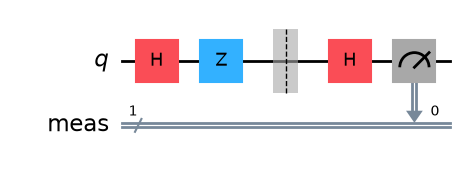

In [6]:
PREPARE = {"|0>": [], "|+>": ["h"], "|->": ["h", "z"], "|+i>": ["h", "s"]}


def build(name, extra_h):
    qubits = QuantumRegister(1, name="q")
    bits = ClassicalRegister(1, name="meas")
    circuit = QuantumCircuit(qubits, bits, name=f"{name}{' then H' if extra_h else ''}")
    for gate in PREPARE[name]:
        getattr(circuit, gate)(qubits[0])
    if extra_h:
        circuit.barrier()
        circuit.h(qubits[0])
    circuit.measure(qubits, bits)
    return circuit


circuits = {}
for name in PREPARE:
    circuits[name] = build(name, extra_h=False)
    circuits[f"{name} then H"] = build(name, extra_h=True)
circuits["|-> then H"].draw("mpl")

A *statevector* is Qiskit's name for the list of amplitudes of a circuit's
state. `Statevector(circuit)` calculates it exactly from the gates, without
running any shots, for a circuit with no measurements. It gives the ideal
answer to compare with. Three pieces of the next cell:
`circuit.remove_final_measurements(inplace=False)` returns a copy of the
circuit with its measurements removed, leaving the original unchanged;
`state.data` is the NumPy array of amplitudes; and `state.probabilities()`
applies the Born rule to every amplitude.

In [7]:
def show(z):
    """Format one amplitude compactly: 0.707, -0.707i, 0.5+0.5i."""
    re, im = round(z.real, 3) + 0, round(z.imag, 3) + 0   # + 0 turns -0.0 into 0.0
    if im == 0:
        return f"{re:g}"
    if re == 0:
        return f"{im:g}i"
    return f"{re:g}{im:+g}i"


ideal_p0 = {}
print("Exact amplitudes (of |0>, |1>) and P(0):")
for label, circuit in circuits.items():
    state = Statevector(circuit.remove_final_measurements(inplace=False))
    ideal_p0[label] = state.probabilities()[0]
    amplitudes = "(" + ", ".join(show(z) for z in state.data) + ")"
    print(f"  {label:12s} {amplitudes:20s}  P(0) = {ideal_p0[label]:.3f}")

Exact amplitudes (of |0>, |1>) and P(0):
  |0>          (1, 0)                P(0) = 1.000
  |0> then H   (0.707, 0.707)        P(0) = 0.500
  |+>          (0.707, 0.707)        P(0) = 0.500
  |+> then H   (1, 0)                P(0) = 1.000
  |->          (0.707, -0.707)       P(0) = 0.500
  |-> then H   (0, 1)                P(0) = 0.000
  |+i>         (0.707, 0.707i)       P(0) = 0.500
  |+i> then H  (0.5+0.5i, 0.5-0.5i)  P(0) = 0.500


### Operator

The operator is either nothing (measure directly) or one $H$ (measure after
$H$). Both end in a Z-basis measurement.

### Execution

In [8]:
isa_circuits = {}
for target in targets:
    pass_manager = generate_preset_pass_manager(
        backend=target.backend, optimization_level=1
    )
    isa_circuits[target.label] = {k: pass_manager.run(c) for k, c in circuits.items()}

pubs = {
    label: [(isa,) for isa in group.values()]
    for label, group in isa_circuits.items()
}

results = {}
for target in targets:
    job = target.sampler.run(pubs[target.label], shots=SETTINGS.shots)
    # None if a hardware job failed or you stopped waiting.
    results[target.label] = target.wait(job)

### Analysis

For each circuit, compare the measured fraction of 0s with the exact $P(0)$.

In [9]:
for label, result in results.items():
    if result is None:
        continue
    print(f"{label}, {SETTINGS.shots} shots:")
    for name, pub_result in zip(circuits, result):
        counts = pub_result.data.meas.get_counts()
        p0 = counts.get("0", 0) / SETTINGS.shots
        print(f"  {name:12s} measured P(0) = {p0:.3f}   exact = {ideal_p0[name]:.3f}")

aer, 4096 shots:
  |0>          measured P(0) = 1.000   exact = 1.000
  |0> then H   measured P(0) = 0.486   exact = 0.500
  |+>          measured P(0) = 0.510   exact = 0.500
  |+> then H   measured P(0) = 1.000   exact = 1.000
  |->          measured P(0) = 0.492   exact = 0.500
  |-> then H   measured P(0) = 0.000   exact = 0.000
  |+i>         measured P(0) = 0.504   exact = 0.500
  |+i> then H  measured P(0) = 0.501   exact = 0.500


Measured directly, $|+\rangle$, $|-\rangle$ and $|{+i}\rangle$ all give about
50/50, as the Born rule predicts. The random scatter of a fraction $p = 0.5$
from $N = 4096$ shots is $\sqrt{p(1-p)/N} = \sqrt{0.25/4096} \approx 0.008$. By
the scatter rule of Notebook 00, most runs put each measured value within
about twice that, 0.016, of 0.500, and an occasional value two to three times
the scatter away is still chance. So their counts look the same. After one
more $H$, $|+\rangle$
returns 0 on every shot and $|-\rangle$ returns 1 on every shot. The coin
picture predicted 50/50 for $|+\rangle$ then $H$; the measurement rules it
out.

$|{+i}\rangle$ followed by $H$ still gives 50/50. Its relative phase,
$\pi/2$, is not one that $H$ converts into a certain result. Notebook 06 builds
a measurement that does.

## Exercises

1. A qubit is in the state $\tfrac{1}{\sqrt5}(|0\rangle - 2i|1\rangle)$. Find
   the probability of each result and check normalization.
2. Find a positive real number $c$ that makes $c(1+i)|0\rangle + c|1\rangle$
   normalized.
3. Is $M = \tfrac{1}{\sqrt2}\begin{pmatrix}1 & 1\\ i & -i\end{pmatrix}$ unitary?
   Which named state does it make from $|0\rangle$? Show that $M = SH$.
4. Show that $Y|+\rangle = -i|-\rangle$. Are $Y|+\rangle$ and $|-\rangle$ the
   same state up to a global phase?
5. Use Notebooks 01 and 02: is the CX matrix unitary? Is the projector $n$?
   Give the reason in each case.
6. True or false: $|+\rangle$ and $|-\rangle$ are the same state, because
   they give the same Z-basis counts. Give the reason.
7. True or false: since $|0\rangle$ and $|1\rangle$ are orthogonal, they are
   90 degrees apart on the Bloch sphere. Give the reason.
8. (hardware) Set `skip_hardware=False` in the Setup cell and run the
   notebook. How close to 1.000 is $P(0)$ for $|+\rangle$ then $H$, and to
   0.000 for $|-\rangle$ then $H$? Compute the scatter
   $\sqrt{p(1-p)/N}$ with the measured $p$, and use the scatter rule of
   Notebook 00: is the gap more than three times the scatter, a real effect?
9. (hardware) On hardware, do the three 50/50 circuits ($|+\rangle$,
   $|-\rangle$, $|{+i}\rangle$ measured directly) agree with 0.500 within
   about twice the scatter of 0.008? If one is more than three times the
   scatter away, which way is it off, and how could the readout of a 1
   described in Notebook 00 explain that?

## What you can now do

1. Compute measurement probabilities from complex amplitudes with the Born
   rule, and check normalization.
2. Test whether a matrix is unitary, and build $Y$, $H$, $P(\varphi)$, $S$ and
   $S^\dagger$ from $a$, $a^\dagger$, $n$ and $\bar n$.
3. Explain why a global phase is never measurable while a relative phase can
   change the result once another gate acts.
4. Place a one-qubit state on the Bloch sphere from its angles $\theta$ and
   $\varphi$.

## Solutions

**Check, Born rule.** $P(1) = |-\tfrac45|^2 = \tfrac{16}{25} = 0.64$.

**Check, inner product.** Conjugate the left vector:
$\tfrac12\big(1\cdot 1 + \bar{i}\cdot(-i)\big) = \tfrac12\big(1 + (-i)(-i)\big) = \tfrac12(1 - 1) = 0$.
Yes, they are orthogonal. These are $|{+i}\rangle$ and $|{-i}\rangle$.

**Check, new operators.** $S|+\rangle = \tfrac{1}{\sqrt2}(S|0\rangle + S|1\rangle) = \tfrac{1}{\sqrt2}(|0\rangle + i|1\rangle) = |{+i}\rangle$.

**Check, phase.** $-|+\rangle$ differs from $|+\rangle$ by the global phase
$-1$, so it is the same state up to a global phase, and every measurement
gives it the same probabilities. $|-\rangle$ differs by a relative phase (only
the $|1\rangle$ amplitude changed sign), so it is a different state.

**Check, Bloch sphere.** The opposite of $+x$ is $-x$, which is $|-\rangle$.

**Exercise 1.** $\alpha = 1/\sqrt5$ gives $P(0) = 1/5 = 0.2$. $\beta = -2i/\sqrt5$
has $\bar\beta = 2i/\sqrt5$, so $P(1) = (-2i)(2i)/5 = -4i^2/5 = 4/5 = 0.8$.
The sum is 1, so the state is normalized.

**Exercise 2.** Normalization needs $|c(1+i)|^2 + |c|^2 = 1$. Since
$|1+i|^2 = (1+i)(1-i) = 2$, this is $c^2(2 + 1) = 1$, so $c = 1/\sqrt3$.
**Check.** $P(0) = 2/3$ and $P(1) = 1/3$ add to 1.

**Exercise 3.** The conjugate transpose is
$M^\dagger = \tfrac{1}{\sqrt2}\begin{pmatrix}1 & -i\\ 1 & i\end{pmatrix}$.
Multiply: the top-left entry of $M^\dagger M$ is $\tfrac12(1\cdot1 + (-i)(i)) = \tfrac12(1 + 1) = 1$;
the top-right is $\tfrac12(1\cdot 1 + (-i)(-i)) = \tfrac12(1 - 1) = 0$; the
bottom row gives 0 and 1 in the same way. So $M^\dagger M = I$ and $M$ is
unitary. The first column, $M|0\rangle = (1, i)^T/\sqrt2$, is $|{+i}\rangle$.
Finally $SH = \begin{pmatrix}1&0\\0&i\end{pmatrix}\tfrac{1}{\sqrt2}\begin{pmatrix}1&1\\1&-1\end{pmatrix} = \tfrac{1}{\sqrt2}\begin{pmatrix}1&1\\ i&-i\end{pmatrix} = M$,
multiplying the second row by $i$.

**Exercise 4.** By linearity, $Y|+\rangle = \tfrac{1}{\sqrt2}(Y|0\rangle + Y|1\rangle) = \tfrac{1}{\sqrt2}(i|1\rangle - i|0\rangle)$.
Factor out $-i$: $-i\cdot\tfrac{1}{\sqrt2}(|0\rangle - |1\rangle) = -i|-\rangle$.
The factor $-i$ multiplies the whole state, so it is a global phase: $Y|+\rangle$
and $|-\rangle$ are the same state up to a global phase.

**Exercise 5.** CX is a permutation matrix (Notebook 02): real entries, and its
transpose undoes it, so $\text{CX}^\dagger\,\text{CX} = I$ and it is unitary.
The projector $n$ is real and equal to its transpose, so $n^\dagger n = n^2 = n$
(a projector satisfies $n^2 = n$, Notebook 01), and $n \neq I$. So $n$ is not
unitary; it sends $|0\rangle$ to the zero vector, which has length 0.

**Exercise 6.** False. They have the same probabilities in the Z basis but a
different relative phase, and Example 3 and the experiment show that one more
$H$ gives 0 for $|+\rangle$ and 1 for $|-\rangle$ on every shot.

**Exercise 7.** False. They are at the north and south poles, 180 degrees
apart. The angle between the two states is 90 degrees, and the Bloch sphere
doubles it.

**Exercise 8.** Expect values a little short of 1.000 and a little above
0.000; the size depends on that day's calibration. With $N = 4096$ and
$p = 0.98$, the scatter is about $\sqrt{0.98 \times 0.02/4096} \approx 0.002$,
so a gap of 0.01 or more, five times the scatter, is a hardware error from the
gates and the readout, not random scatter. The superposition picture still
holds: the coin picture predicts 0.5, far from anything the hardware returns.

**Exercise 9.** With $p = 0.5$ the scatter is $\sqrt{0.25/4096} \approx 0.008$.
Expect the three values within about 0.016 of 0.5 on most runs. If one is
more than three times the scatter (about 0.024) away, expect its measured
$P(0)$ to be above 0.5: a qubit that should read 1 sometimes drops to 0 before
its readout finishes (Notebook 00), which adds 0s and removes 1s.

## Terms introduced in this notebook

| Term | Meaning |
|---|---|
| amplitude | a complex entry of a state vector: $\alpha$ for $\lvert 0\rangle$, $\beta$ for $\lvert 1\rangle$ |
| superposition | a state with more than one nonzero amplitude |
| Born rule | a Z-basis measurement gives 0 with probability $\lvert\alpha\rvert^2$ and 1 with probability $\lvert\beta\rvert^2$, and leaves the measured basis state; for several qubits, bitstring $x$ is measured with probability $\lvert c_x\rvert^2$, the squared modulus of its amplitude |
| normalization | $\lvert\alpha\rvert^2 + \lvert\beta\rvert^2 = 1$, equivalently $\langle\psi\vert\psi\rangle = 1$; for several qubits $\sum_x \lvert c_x\rvert^2 = 1$ |
| conjugate transpose $M^\dagger$ | the transpose with every entry conjugated; reverses products, $(AB)^\dagger = B^\dagger A^\dagger$ |
| inner product $\langle\phi\vert\psi\rangle$ | $\sum_k \overline{\phi_k}\psi_k$ |
| orthogonal states | states with $\langle\phi\vert\psi\rangle = 0$ |
| overlap | $\lvert\langle\phi\vert\psi\rangle\rvert^2$, the probability of the result for $\lvert\phi\rangle$ in a measurement that tells $\lvert\phi\rangle$ from its orthogonal states |
| unitary operator | a matrix with $U^\dagger U = I$, equivalently with normalized, mutually orthogonal columns; every gate is one, and $U^\dagger$ undoes it |
| Pauli $Y$ | $i(a^\dagger - a)$ |
| Hadamard $H$ | $(X + Z)/\sqrt2$; $H\lvert 0\rangle = \lvert +\rangle$, $H\lvert 1\rangle = \lvert -\rangle$ |
| $\lvert\pm\rangle$, $\lvert\pm i\rangle$ | $(\lvert 0\rangle \pm \lvert 1\rangle)/\sqrt2$ and $(\lvert 0\rangle \pm i\lvert 1\rangle)/\sqrt2$ |
| phase gate $P(\varphi)$ | $\bar n + e^{i\varphi}n$; $S = P(\pi/2)$, $S^\dagger = P(-\pi/2)$, $Z = P(\pi)$ |
| global phase | a factor $e^{i\gamma}$ on the whole state; never measurable |
| relative phase | the phase of $\beta$ compared with the phase of $\alpha$ |
| Bloch sphere | the unit sphere on which $\cos\frac{\theta}{2}\lvert 0\rangle + e^{i\varphi}\sin\frac{\theta}{2}\lvert 1\rangle$ is the point with polar angle $\theta$ and azimuth $\varphi$; $\lvert 0\rangle$ at $+z$, $\lvert 1\rangle$ at $-z$, $\lvert +\rangle$ at $+x$, $\lvert -\rangle$ at $-x$, $\lvert {+i}\rangle$ at $+y$, $\lvert {-i}\rangle$ at $-y$; orthogonal states are opposite points |
| angle between two states | the angle $\delta$ in $[0, \pi/2]$ with $\cos\delta = \lvert\langle\phi\vert\psi\rangle\rvert$; the Bloch-sphere points are $2\delta$ apart, so the overlap is $\cos^2$ of half the sphere angle |
| statevector | Qiskit's exact list of a circuit's amplitudes, calculated without shots |
| barrier | a Qiskit instruction that stops the transpiler from combining or canceling gates across it |